In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_22858/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset2_JavaScript_model_dataset2_JavaScript_similarities.csv"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq2_JavaScript/RESULTS/results_evaluate_dataset2_JavaScript_combination_rq2_JavaScript_seed-3022024.xlsx"

DATASET2_COMPLETE = f"{DATA_PATH}/dataset2_JavaScript_complete.json" 
DATASET2_TESTING = f"{DATA_PATH}/dataset2_JavaScript_testing.json"
DATASET2_METADATA = f"{DATA_PATH}/dataset2_JavaScript_metadata.json"

## Dataset2

In [3]:
df_complete = pd.read_json(DATASET2_COMPLETE)

In [4]:
df_test = pd.read_json(DATASET2_TESTING)
df_test

,all_raw_base,all_raw_a,all_raw_b,all_raw_res,merge_id,chunk_number
0,"},{""../lang/isArray"":144,""./bindCallback"":98}]...","},{""../lang/isArray"":141,""./bindCallback"":95}]...","\n},{""../lang/isArray"":142,""./bindCallback"":96...","},{""../lang/isArray"":141,""./bindCallback"":95}]...",23593,76
1,"\t},\n\t\n\trefreshGrid : function(fromGridEle...","},\n\n refreshGrid: function(fromGridEl...","\n\t},\n\t\n\trefreshGrid : function(fromGridE...","},\n\n refreshGrid: function(fromGridEl...",77774,3
2,\t setShowChildren: function(visible){\n\t ...,\t verifyProps: function () {\n\t if...,\n\t setShowChildren: function(visible){\n\...,\t verifyProps: function () {\n\t if...,61241,13
3,"\t\t\tslotWidth = mathMin(axis.slotWidth, slot...","\t\t\tslotWidth = Math.min(axis.slotWidth, slo...","\n\t\t\tslotWidth = mathMin(axis.slotWidth, sl...","\t\t\tslotWidth = Math.min(axis.slotWidth, slo...",118829,16
4,"},{""./_descriptors"":30,""./_export"":34,""./_obje...","\n},{""./_descriptors"":31,""./_export"":35,""./_ob...","\n\n},{""./_descriptors"":31,""./_export"":35,""./_...","\n},{""./_descriptors"":31,""./_export"":35,""./_ob...",155033,245
...,...,...,...,...,...,...
5144,"$routeProvider.when('/images/:id/', {t...","$routeProvider.when('/images/:id*/', {...","\n $routeProvider.when('/images/:id/', ...","$routeProvider.when('/images/:id*/', {...",203419,1
5145,"<Image className=""theme-cover"" src...","<Image className=""theme-cover"" src...",\n,,34496,2
5146,if (process.env.NODE_ENV === 'production') {\n...,"function bailoutHooks(current, workInProgress,...",\nif (process.env.NODE_ENV === 'production') {...,"function bailoutHooks(current, workInProgress,...",43162,28
5147,WebhookEndpoint.getFresh({id: $rou...,\n $q.all([\n FormEndp...,\n // @uirouter-refactor this is ve...,\n $q.all([\n FormEndp...,122669,3


In [5]:
df_mergegen = pd.read_csv(MERGEGEN_DATASET2)
data = []
for index, row in df_mergegen.iterrows():
    chunk = df_complete.iloc[row['chunk_index']]
    chunk_id = f"{chunk['merge_id']}-{chunk['chunk_number']}"
    data.append(chunk_id)
df_mergegen['chunk_id'] = data
df_mergegen = df_mergegen.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen.sort_values('chunk_id')
df_mergegen

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
0,27472,0.750000,0.666667,0.040468,1.000000,0.833333,0.916667,FAIL,196911-655
1,44031,0.997118,0.996904,0.342645,0.632911,0.948012,0.790462,FAIL,132648-2
2,35805,0.413514,0.416901,1.357956,0.416901,0.811475,0.614188,FAIL,55561-5
3,5646,0.763158,0.747664,0.307735,0.679012,0.654088,0.666550,FAIL,186409-1
4,17768,0.067797,0.037855,1.354022,0.096552,0.079395,0.087973,FAIL,132448-1
...,...,...,...,...,...,...,...,...,...
5144,1777,1.000000,1.000000,0.133554,1.000000,0.818182,0.909091,SUCCEED,179265-35
5145,41526,1.000000,1.000000,0.314328,1.000000,1.000000,1.000000,SUCCEED,89711-7
5146,24635,1.000000,1.000000,0.168448,1.000000,0.706897,0.853448,SUCCEED,187801-4
5147,37477,0.842553,1.000000,1.035379,0.665687,0.399317,0.532502,SUCCEED,161382-1


In [6]:
df_mergegen.describe()

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim
count,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000,5149.000000
mean,25465.772577,0.867368,0.859217,0.520664,0.709729,0.670368,0.690048
std,14789.406424,0.238136,0.263065,0.459070,0.322154,0.335929,0.240918
min,4.000000,0.000000,0.000000,0.027127,0.000000,0.000000,0.000000
25%,12683.000000,0.787234,0.840532,0.174119,0.534428,0.447387,0.544152
50%,25379.000000,1.000000,1.000000,0.316305,0.834951,0.790698,0.709928
75%,38330.000000,1.000000,1.000000,0.728654,0.976109,0.962963,0.893258
max,51469.000000,1.000000,1.000000,1.530960,1.000000,1.000000,1.000000


In [7]:
df_sbcr = pd.read_excel(SBCR_DATASET2)
df_sbcr = df_sbcr.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
926,100159-1,0.902690,0.994778,ok,12.939296
1032,10096-1,0.926265,0.980803,ok,3.973917
1062,101479-1,0.643705,0.719136,ok,12.103017
995,101524-1,0.601941,0.292103,ok,65.247741
960,101528-1,0.916118,0.946363,ok,22.631450
...,...,...,...,...,...
1156,99230-1,0.993080,1.000000,ok,24.513543
416,9947-2,0.874936,0.735484,ok,7.194102
109,99477-1,0.901962,0.642943,ok,3.712581
477,99588-1,0.913930,1.000000,ok,19.721328


In [8]:
df_results = df_sbcr[['chunk_id', 'fitness_sbcr', 'sim_sbcr', 'time_sbcr']].merge(df_mergegen[['chunk_index', 'chunk_id', 'sim_mergegen', 'time_mergegen', 'mergegen_parents_sim']], on='chunk_id', suffixes=('_sbcr', '_mergegen'))
df_results

,chunk_id,fitness_sbcr,sim_sbcr,time_sbcr,chunk_index,sim_mergegen,time_mergegen,mergegen_parents_sim
0,4314-130,0.839161,1.000000,22.699592,8140,1.000000,0.168681,0.827331
1,161562-10,0.978183,0.959641,22.313421,26525,1.000000,0.262166,0.972083
2,156864-1,0.876318,0.747664,21.497840,44495,1.000000,0.186749,0.861000
3,37347-2,0.811602,1.000000,23.151990,42547,1.000000,0.201570,0.814852
4,194169-2,0.801728,0.648373,4.807784,30716,0.922025,1.348341,0.777483
...,...,...,...,...,...,...,...,...
1302,146509-2,0.910324,0.932765,21.175079,32859,0.978890,1.354858,0.963552
1303,68491-34,0.599088,0.991239,0.828199,10797,1.000000,0.616231,0.594733
1304,193794-4,0.855649,0.975684,1.564690,6000,1.000000,0.483217,0.826774
1305,90072-300,0.829473,0.848485,2.340068,42473,0.717949,0.370072,0.667072


In [9]:
print(df_results['sim_sbcr'].isnull().sum()) 
df_results_clean = df_results.dropna(subset=['sim_sbcr', 'sim_mergegen'])

12


In [10]:
print(df_results_clean[['sim_sbcr', 'sim_mergegen', 'time_sbcr', 'time_mergegen']].describe())

          sim_sbcr  sim_mergegen    time_sbcr  time_mergegen
count  1295.000000   1295.000000  1295.000000    1295.000000
mean      0.814622      0.877370    14.814825       0.531898
std       0.210181      0.223208    17.080710       0.449940
min       0.003898      0.000000     0.257957       0.040358
25%       0.706919      0.835708     3.069293       0.193806
50%       0.887179      1.000000    13.380127       0.334574
75%       0.994127      1.000000    22.536076       0.713305
max       1.000000      1.000000   231.273514       1.367894


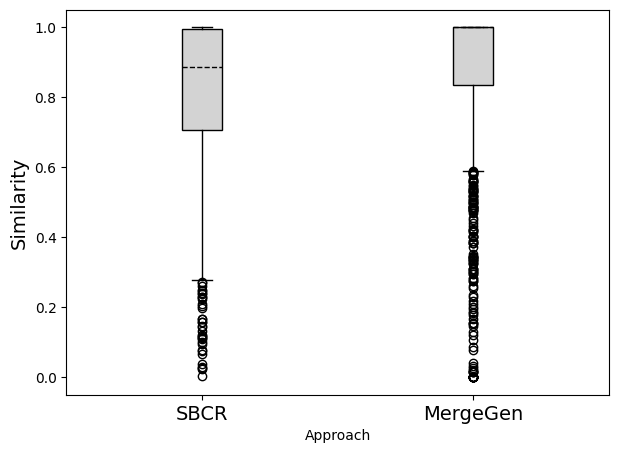

In [11]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

In [12]:
from scipy import stats

# Normality test
stat_shapiro_sbcr, p_shapiro_sbcr = stats.shapiro(df_results_clean['sim_sbcr'])
stat_shapiro_mergegen, p_shapiro_mergegen = stats.shapiro(df_results_clean['sim_mergegen'])

print(f"Shapiro-Wilk Test for SBCR: W={stat_shapiro_sbcr}, p={p_shapiro_sbcr}")
print(f"Shapiro-Wilk Test for MergeGen: W={stat_shapiro_mergegen}, p={p_shapiro_mergegen}")

# Homocedasticity test
stat_levene, p_levene = stats.levene(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])

print(f"Levene Test: W={stat_levene}, p={p_levene}")

# Significance test
if p_shapiro_sbcr > 0.05 and p_shapiro_mergegen > 0.05 and p_levene > 0.05:
    # if they are normal and homocedastic, we use t-test
    stat_ttest, p_ttest = stats.ttest_ind(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])
    print(f"T-Test: t={stat_ttest}, p={p_ttest}")
else:
    # Otherwise, we use Mann-Whitney U
    stat_mannwhitney, p_mannwhitney = stats.mannwhitneyu(df_results_clean['sim_sbcr'], df_results_clean['sim_mergegen'])
    print(f"Mann-Whitney U Test: U={stat_mannwhitney}, p={p_mannwhitney}")


Shapiro-Wilk Test for SBCR: W=0.833167607219984, p=9.530275693730294e-35
Shapiro-Wilk Test for MergeGen: W=0.6214137320629137, p=1.2598699498259456e-46
Levene Test: W=21.625556658336592, p=3.4805564749504185e-06
Mann-Whitney U Test: U=574899.5, p=3.55681138465395e-46


In [13]:
import numpy as np
from scipy.stats import mannwhitneyu

sim_sbcr = df_results_clean['sim_sbcr']
sim_mergegen = df_results_clean['sim_mergegen']

u_stat, p_value = mannwhitneyu(sim_sbcr, sim_mergegen, alternative='two-sided')

n1, n2 = len(sim_sbcr), len(sim_mergegen)
n = n1 + n2

from scipy.stats import norm
z_value = norm.ppf(1 - p_value / 2)
r = z_value / np.sqrt(n)

print("Mann-Whitney U statistic:", u_stat)
print("p-value:", p_value)
print("Z-value:", z_value)
print("Effect size (r):", r)

Mann-Whitney U statistic: 574899.5
p-value: 3.55681138465395e-46
Z-value: inf
Effect size (r): inf


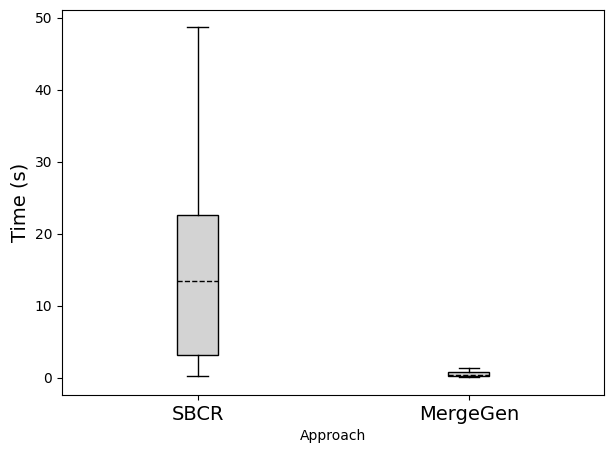

In [14]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_results_clean['time_sbcr'], df_results_clean['time_mergegen']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)
# plt.title('Similarity between random candidates and parents \n using each aggregation function', fontsize=16)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  